# 04. BERTopic, Hướng B, A4 và tổng hợp kết quả (TV4)

**Đầu vào:** `articles.csv`, `embeddings/*.npy`, `embedding_time.csv`, các dòng A1–A3 trong `results.csv`.
**Đầu ra:** dòng `bertopic` trong `results.csv`; `bertopic_k6`, `bertopic_hdbscan` trong `topic_words.csv`;
cột `x, y, bertopic_k6, bertopic_hdbscan` của `doc_topics.csv`; `models/bertopic_best/`; `fig1`–`fig5`.

Cách dùng: **Restart kernel → Run All**. Toàn bộ chạy khoảng 10–15 phút trên CPU (embedding đã tính sẵn).

In [1]:
import sys; sys.path.append("..")
from src.config import *

In [2]:
import logging
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter

from src.bertopic_runner import (coords_2d, fit_bertopic, get_topic_words, load_bertopic,
                                 predict_bertopic, reduce_noise, save_bertopic)
from src.embed import load_embedding
from src.metrics import evaluate, make_row, save_results
from src.preprocess import get_tokens, load_articles

logging.getLogger("BERTopic").setLevel(logging.ERROR)   # bỏ cảnh báo "không có embedding model" (cố ý)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", None)

df = load_articles()
docs = df["text_tok"].tolist()        # BERTopic rút từ khóa c-TF-IDF trên text_tok
texts = get_tokens(df)                # cho C_v
y_true = df["true_label"].values      # chỉ dùng để chấm điểm
emb_time = pd.read_csv(EMB_TIME_CSV).set_index("embedding")["time_s"]
X = {key: load_embedding(key) for key in EMBEDDINGS}
print("Số bài:", len(df), "| embedding:", {k: v.shape[1] for k, v in X.items()})

W1123 11:10:10.773000 98166 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Số bài: 1800 | embedding: {'b0_tfidf_svd': 100, 'b1_mbert_cls': 768, 'b2_mbert_mean': 768, 'b3_minilm': 384, 'b4_vi_sbert': 768, 'b5_e5': 768}


## 1. Hướng B: 6 embedding × 2 chế độ × 3 seed

- `k6`: UMAP → K-Means 6 cụm (so sánh công bằng với LDA/LSA).
- `hdbscan`: UMAP → HDBSCAN, quét `min_cluster_size` ∈ `MIN_CLUSTER_SIZES`.
- `time_s` = thời gian embedding (`embedding_time.csv`) + thời gian fit BERTopic (QUY_UOC §5.1).
- ARI/NMI/Purity của chế độ `hdbscan` tính trên văn bản **không** thuộc cụm nhiễu; tỉ lệ nhiễu ở `pct_noise`.

In [3]:
def mcs_param(mcs):
    return f"min_cluster_size={mcs}"


def chay(key, mode, seed, mcs=DEFAULT_MIN_CLUSTER_SIZE):
    """Fit 1 cấu hình, chấm điểm. Trả về (model, labels, topic_words, row của results.csv)."""
    t0 = time.perf_counter()
    model, labels = fit_bertopic(docs, X[key], mode, seed=seed, min_cluster_size=mcs)
    t_fit = time.perf_counter() - t0
    words = get_topic_words(model)
    scores = evaluate(labels, y_true, words, texts)
    param = "" if mode == "k6" else mcs_param(mcs)
    row = make_row("bertopic", key, mode, param, seed, scores, float(emb_time[key]) + t_fit)
    return model, labels, words, row


configs = [("k6", DEFAULT_MIN_CLUSTER_SIZE)] + [("hdbscan", m) for m in MIN_CLUSTER_SIZES]
rows, t_start = [], time.perf_counter()
for key in EMBEDDINGS:
    for mode, mcs in configs:
        part = [chay(key, mode, seed, mcs)[3] for seed in SEEDS]
        rows += part
        r = pd.DataFrame(part)
        label = "" if mode == "k6" else mcs_param(mcs)
        print(f"{key:14s} {mode:7s} {label:20s} NMI={r.nmi.mean():.3f}  C_v={r.cv.mean():.3f}  "
              f"chủ đề={r.n_topics.mean():.1f}  nhiễu={r.pct_noise.mean():.1%}")
save_results(rows)
print(f"Đã ghi {len(rows)} dòng bertopic vào results.csv ({time.perf_counter() - t_start:.0f}s)")

b0_tfidf_svd   k6                           NMI=0.626  C_v=0.820  chủ đề=6.0  nhiễu=0.0%


b0_tfidf_svd   hdbscan min_cluster_size=15  NMI=0.580  C_v=0.785  chủ đề=33.7  nhiễu=18.5%


b0_tfidf_svd   hdbscan min_cluster_size=30  NMI=0.647  C_v=0.810  chủ đề=12.0  nhiễu=19.7%


b0_tfidf_svd   hdbscan min_cluster_size=50  NMI=0.657  C_v=0.794  chủ đề=5.0  nhiễu=2.8%


b1_mbert_cls   k6                           NMI=0.376  C_v=0.661  chủ đề=6.0  nhiễu=0.0%


b1_mbert_cls   hdbscan min_cluster_size=15  NMI=0.035  C_v=0.482  chủ đề=2.7  nhiễu=0.4%


... (14 outputs left out)

b5_e5          k6                           NMI=0.647  C_v=0.711  chủ đề=6.0  nhiễu=0.0%


b5_e5          hdbscan min_cluster_size=15  NMI=0.635  C_v=0.753  chủ đề=18.0  nhiễu=20.2%


b5_e5          hdbscan min_cluster_size=30  NMI=0.627  C_v=0.825  chủ đề=5.0  nhiễu=2.1%


b5_e5          hdbscan min_cluster_size=50  NMI=0.623  C_v=0.825  chủ đề=5.0  nhiễu=4.6%
Đã ghi 72 dòng bertopic vào results.csv (447s)


In [4]:
res = pd.read_csv(RESULTS_CSV, keep_default_na=False)
bt = res[res["method"] == "bertopic"]
cols = ["n_topics", "pct_noise", "ari", "nmi", "purity", "cv", "diversity", "time_s"]
bt.groupby(["embedding", "mode", "param"], sort=False)[cols].mean().round(4)

n_topics  pct_noise     ari  \
embedding     mode    param                                              
b0_tfidf_svd  k6                             6.0000     0.0000  0.4604   
              hdbscan min_cluster_size=15   33.6667     0.1848  0.4408   
                      min_cluster_size=30   12.0000     0.1974  0.5517   
                      min_cluster_size=50    5.0000     0.0283  0.4787   
b1_mbert_cls  k6                             6.0000     0.0000  0.2852   
              hdbscan min_cluster_size=15    2.6667     0.0035  0.0026   
                      min_cluster_size=30    2.0000     0.0000  0.0004   
                      min_cluster_size=50    2.0000     0.0000  0.0004   
b2_mbert_mean k6                             6.0000     0.0000  0.4446   
              hdbscan min_cluster_size=15   18.3333     0.2094  0.4331   
                      min_cluster_size=30    9.6667     0.1646  0.3577   
                      min_cluster_size=50    3.3333     0.0391  0.1737   
b3_minilm     k6                             6.0000     0.0000  0.5492   
              hdbscan min_cluster_size=15   24.3333     0.1784  0.4203   
                      min_cluster_size=30    8.6667     0.1843  0.3666   
                      min_cluster_size=50    3.6667     0.0870  0.1812   
b4_vi_sbert   k6                             6.0000     0.0000  0.5404   
              hdbscan min_cluster_size=15   23.3333     0.2608  0.5151   
                      min_cluster_size=30    6.6667     0.1045  0.2486   
                      min_cluster_size=50    7.3333     0.1435  0.3898   
b5_e5         k6                             6.0000     0.0000  0.6231   
              hdbscan min_cluster_size=15   18.0000     0.2018  0.5986   
                      min_cluster_size=30    5.0000     0.0211  0.4324   
                      min_cluster_size=50    5.0000     0.0457  0.4261   

                                              nmi  purity      cv  diversity  \
embedding     mode    param                                                    
b0_tfidf_svd  k6                           0.6265  0.6324  0.8198     0.9778   
              hdbscan min_cluster_size=15  0.5799  0.8794  0.7853     0.8329   
                      min_cluster_size=30  0.6465  0.8058  0.8103     0.8916   
                      min_cluster_size=50  0.6573  0.6381  0.7943     0.9800   
b1_mbert_cls  k6                           0.3758  0.5181  0.6606     0.8278   
              hdbscan min_cluster_size=15  0.0350  0.1907  0.4821     0.9000   
                      min_cluster_size=30  0.0104  0.1767  0.4500     0.9000   
                      min_cluster_size=50  0.0104  0.1767  0.4500     0.9000   
b2_mbert_mean k6                           0.5058  0.6656  0.6745     0.9222   
              hdbscan min_cluster_size=15  0.5351  0.7742  0.7429     0.8683   
                      min_cluster_size=30  0.4549  0.6200  0.6942     0.9185   
                      min_cluster_size=50  0.3411  0.4003  0.6803     0.9833   
b3_minilm     k6                           0.5910  0.7550  0.7189     0.9389   
              hdbscan min_cluster_size=15  0.5429  0.8159  0.7825     0.8627   
                      min_cluster_size=30  0.4213  0.6181  0.7437     0.8944   
                      min_cluster_size=50  0.2253  0.3695  0.6911     0.9667   
b4_vi_sbert   k6                           0.5827  0.7172  0.7587     0.9667   
              hdbscan min_cluster_size=15  0.5888  0.8548  0.7733     0.8732   
                      min_cluster_size=30  0.4240  0.5007  0.7735     0.9100   
                      min_cluster_size=50  0.5538  0.6241  0.7944     0.9119   
b5_e5         k6                           0.6466  0.8093  0.7108     0.9667   
              hdbscan min_cluster_size=15  0.6347  0.8791  0.7533     0.8390   
                      min_cluster_size=30  0.6269  0.6233  0.8250     0.8600   
                      min_cluster_size=50  0.6229  0.6182  0.8246     0.8600   

                                     

## 2. Chọn `BEST_EMBEDDING`

Theo KE_HOACH §6.2 và QUY_UOC §2: mô hình BERT có **NMI trung bình 3 seed cao nhất ở BERTopic chế độ k = 6**.
B0 không dùng BERT nên chỉ là mốc đối chứng, không tham gia chọn (giống notebook 03).

In [5]:
bert_keys = [k for k in EMBEDDINGS if EMBEDDINGS[k]["model"] is not None]
k6 = bt[bt["mode"] == "k6"]
nmi_k6 = k6.groupby("embedding")["nmi"].agg(["mean", "std"]).reindex(list(EMBEDDINGS)).round(4)
display(nmi_k6.rename(columns={"mean": "NMI k6 (TB)", "std": "độ lệch chuẩn"}))
best_emb = nmi_k6.loc[bert_keys, "mean"].idxmax()
print("BEST_EMBEDDING chọn:", best_emb, "| giá trị hiện tại trong config:", BEST_EMBEDDING)
if best_emb != BEST_EMBEDDING:
    print(f"→ Cập nhật src/config.py: BEST_EMBEDDING = \"{best_emb}\" (báo TV3, TV5)")

,NMI k6 (TB),độ lệch chuẩn
embedding,,
b0_tfidf_svd,0.6265,0.0028
b1_mbert_cls,0.3758,0.0011
b2_mbert_mean,0.5058,0.0073
b3_minilm,0.5910,0.0049
b4_vi_sbert,0.5827,0.0069
b5_e5,0.6466,0.0043


BEST_EMBEDDING chọn: b5_e5 | giá trị hiện tại trong config: b5_e5


## 3. Chọn `min_cluster_size`

Chọn theo **chỉ số nội C_v** (trung bình 3 seed) trên `BEST_EMBEDDING`, không dùng nhãn thật (KE_HOACH §6.4).
NMI chỉ in ra để tham khảo.

In [6]:
hd = bt[bt["mode"] == "hdbscan"]
mcs_tab = (hd.groupby(["embedding", "param"], sort=False)[["n_topics", "pct_noise", "cv", "diversity", "nmi"]]
             .mean().round(4))
display(mcs_tab.loc[best_emb])
cv_by_mcs = hd[hd["embedding"] == best_emb].groupby("param")["cv"].mean()
best_param = cv_by_mcs.idxmax()
best_mcs = int(best_param.split("=")[1])
print("min_cluster_size chọn (C_v cao nhất):", best_mcs, "| config hiện tại:", BEST_MIN_CLUSTER_SIZE)

,n_topics,pct_noise,cv,diversity,nmi
param,,,,,
min_cluster_size=15,18.0,0.2018,0.7533,0.839,0.6347
min_cluster_size=30,5.0,0.0211,0.8250,0.860,0.6269
min_cluster_size=50,5.0,0.0457,0.8246,0.860,0.6229


min_cluster_size chọn (C_v cao nhất): 30 | config hiện tại: 30


In [7]:
# toàn bộ embedding (cho mục 2 của ket_qua/04)
mcs_tab

n_topics  pct_noise      cv  diversity  \
embedding     param                                                         
b0_tfidf_svd  min_cluster_size=15   33.6667     0.1848  0.7853     0.8329   
              min_cluster_size=30   12.0000     0.1974  0.8103     0.8916   
              min_cluster_size=50    5.0000     0.0283  0.7943     0.9800   
b1_mbert_cls  min_cluster_size=15    2.6667     0.0035  0.4821     0.9000   
              min_cluster_size=30    2.0000     0.0000  0.4500     0.9000   
              min_cluster_size=50    2.0000     0.0000  0.4500     0.9000   
b2_mbert_mean min_cluster_size=15   18.3333     0.2094  0.7429     0.8683   
              min_cluster_size=30    9.6667     0.1646  0.6942     0.9185   
              min_cluster_size=50    3.3333     0.0391  0.6803     0.9833   
b3_minilm     min_cluster_size=15   24.3333     0.1784  0.7825     0.8627   
              min_cluster_size=30    8.6667     0.1843  0.7437     0.8944   
              min_cluster_size=50    3.6667     0.0870  0.6911     0.9667   
b4_vi_sbert   min_cluster_size=15   23.3333     0.2608  0.7733     0.8732   
              min_cluster_size=30    6.6667     0.1045  0.7735     0.9100   
              min_cluster_size=50    7.3333     0.1435  0.7944     0.9119   
b5_e5         min_cluster_size=15   18.0000     0.2018  0.7533     0.8390   
              min_cluster_size=30    5.0000     0.0211  0.8250     0.8600   
              min_cluster_size=50    5.0000     0.0457  0.8246     0.8600   

                                      nmi  
embedding     param                        
b0_tfidf_svd  min_cluster_size=15  0.5799  
              min_cluster_size=30  0.6465  
              min_cluster_size=50  0.6573  
b1_mbert_cls  min_cluster_size=15  0.0350  
              min_cluster_size=30  0.0104  
              min_cluster_size=50  0.0104  
b2_mbert_mean min_cluster_size=15  0.5351  
              min_cluster_size=30  0.4549  
              min_cluster_size=50  0.3411  
b3_minilm     min_cluster_size=15  0.5429  
              min_cluster_size=30  0.4213  
              min_cluster_size=50  0.2253  
b4_vi_sbert   min_cluster_size=15  0.5888  
              min_cluster_size=30  0.4240  
              min_cluster_size=50  0.5538  
b5_e5         min_cluster_size=15  0.6347  
              min_cluster_size=30  0.6269  
              min_cluster_size=50  0.6229

## 4. Bảng 1: Hướng A (trung bình ± độ lệch chuẩn 3 seed)

A3 và A4 dùng cùng `BEST_EMBEDDING`. A4 có 2 dòng:
- **A4 (k = 6)**: UMAP + K-Means. A3 → A4 (k = 6) đo riêng tác động của **UMAP**.
- **A4 (HDBSCAN)**: pipeline BERTopic đầy đủ. A4 (k = 6) → A4 (HDBSCAN) đo tác động của **HDBSCAN** (số chủ đề tự xác định, có nhiễu).

In [8]:
def pick(method, embedding, mode, param):
    return res[(res["method"] == method) & (res["embedding"] == embedding)
               & (res["mode"] == mode) & (res["param"] == param)]


A_ROWS = [
    ("A1. LDA", "lda", "bow", "k6", ""),
    ("A2. LSA + K-Means", "lsa_kmeans", "tfidf_svd", "k6", f"svd_dim={BEST_SVD_DIM}"),
    ("A3. BERT + K-Means", "bert_kmeans", best_emb, "k6", ""),
    ("A4. BERTopic (k = 6)", "bertopic", best_emb, "k6", ""),
    ("A4. BERTopic (HDBSCAN)", "bertopic", best_emb, "hdbscan", best_param),
]
M_COLS = ["ari", "nmi", "purity", "cv", "diversity", "time_s", "n_topics", "pct_noise"]
bang1 = []
for name, *key in A_ROWS:
    g = pick(*key)
    if len(g) < len(SEEDS):
        print(f"CẢNH BÁO: {name} chỉ có {len(g)} seed trong results.csv")
    bang1.append({"Phương pháp": name, "n_seed": len(g),
                  **{f"{c}": g[c].mean() for c in M_COLS}, **{f"{c}_std": g[c].std() for c in M_COLS}})
bang1 = pd.DataFrame(bang1).set_index("Phương pháp")
bang1[["n_seed"] + M_COLS].round(4)

,n_seed,ari,nmi,purity,cv,diversity,time_s,n_topics,pct_noise
Phương pháp,,,,,,,,,
A1. LDA,3,0.4481,0.5028,0.6522,0.6790,0.9222,23.6363,6.0,0.0000
A2. LSA + K-Means,3,0.5722,0.6511,0.7863,0.7918,0.9778,2.0307,6.0,0.0000
A3. BERT + K-Means,3,0.5312,0.5838,0.7239,0.7196,0.9611,129.5696,6.0,0.0000
A4. BERTopic (k = 6),3,0.6231,0.6466,0.8093,0.7108,0.9667,132.9711,6.0,0.0000
A4. BERTopic (HDBSCAN),3,0.4324,0.6269,0.6233,0.8250,0.8600,132.9877,5.0,0.0211


## 5. Bảng 2: Hướng B (trung bình 3 seed; chế độ HDBSCAN dùng `min_cluster_size` đã chọn)

In [9]:
SHORT = {"b0_tfidf_svd": "B0. TF-IDF + SVD", "b1_mbert_cls": "B1. mBERT [CLS]",
         "b2_mbert_mean": "B2. mBERT mean pooling", "b3_minilm": "B3. Multilingual MiniLM",
         "b4_vi_sbert": "B4. Vietnamese-SBERT", "b5_e5": "B5. Multilingual-E5"}
bang2 = []
for key in EMBEDDINGS:
    a, b = pick("bertopic", key, "k6", ""), pick("bertopic", key, "hdbscan", best_param)
    bang2.append({"Mô hình": SHORT[key], "key": key,
                  "nmi_k6": a.nmi.mean(), "nmi_k6_std": a.nmi.std(), "ari_k6": a.ari.mean(),
                  "nmi_hdb": b.nmi.mean(), "cv_k6": a.cv.mean(), "cv_hdb": b.cv.mean(),
                  "div_k6": a.diversity.mean(), "n_topics_hdb": b.n_topics.mean(),
                  "noise_hdb": b.pct_noise.mean(), "emb_time": float(emb_time[key])})
bang2 = pd.DataFrame(bang2).set_index("Mô hình")
bang2.drop(columns="key").round(4)

,nmi_k6,nmi_k6_std,ari_k6,nmi_hdb,cv_k6,cv_hdb,div_k6,n_topics_hdb,noise_hdb,emb_time
Mô hình,,,,,,,,,,
B0. TF-IDF + SVD,0.6265,0.0028,0.4604,0.6465,0.8198,0.8103,0.9778,12.0000,0.1974,1.1355
B1. mBERT [CLS],0.3758,0.0011,0.2852,0.0104,0.6606,0.4500,0.8278,2.0000,0.0000,182.6839
B2. mBERT mean pooling,0.5058,0.0073,0.4446,0.4549,0.6745,0.6942,0.9222,9.6667,0.1646,173.1924
B3. Multilingual MiniLM,0.5910,0.0049,0.5492,0.4213,0.7189,0.7437,0.9389,8.6667,0.1843,37.4062
B4. Vietnamese-SBERT,0.5827,0.0069,0.5404,0.4240,0.7587,0.7735,0.9667,6.6667,0.1045,104.4018
B5. Multilingual-E5,0.6466,0.0043,0.6231,0.6269,0.7108,0.8250,0.9667,5.0000,0.0211,129.1212


## 6. Xử lý cụm nhiễu (`BEST_EMBEDDING`, HDBSCAN, `min_cluster_size` đã chọn)

1. Bỏ văn bản nhiễu khi tính ARI/NMI (như `results.csv`).
2. `reduce_noise` (= `reduce_outliers(strategy="embeddings")`) gán văn bản nhiễu vào chủ đề gần nhất, rồi tính trên toàn bộ.

In [10]:
noise_rows = []
for seed in SEEDS:
    model, labels, words, _ = chay(best_emb, "hdbscan", seed, best_mcs)
    s1 = evaluate(labels, y_true, words, texts)
    s2 = evaluate(reduce_noise(model, docs, labels, X[best_emb]), y_true, words, texts)
    noise_rows.append({"seed": seed, "pct_noise": s1["pct_noise"], "ari_bo_nhieu": s1["ari"], "nmi_bo_nhieu": s1["nmi"],
                       "ari_reduce": s2["ari"], "nmi_reduce": s2["nmi"]})
noise_tab = pd.DataFrame(noise_rows).set_index("seed")
display(noise_tab.round(4))
noise_tab.agg(["mean", "std"]).round(4)

,pct_noise,ari_bo_nhieu,nmi_bo_nhieu,ari_reduce,nmi_reduce
seed,,,,,
42,0.0150,0.4300,0.6263,0.4321,0.6227
43,0.0283,0.4336,0.6280,0.4332,0.6224
44,0.0200,0.4337,0.6265,0.4342,0.6225


,pct_noise,ari_bo_nhieu,nmi_bo_nhieu,ari_reduce,nmi_reduce
mean,0.0211,0.4324,0.6269,0.4332,0.6225
std,0.0067,0.0021,0.0010,0.0010,0.0002


## 7. Mô hình chốt (seed 42): chủ đề, `topic_words.csv`, `doc_topics.csv`, lưu mô hình

- `models/bertopic_best/` lưu mô hình **k = 6** của `BEST_EMBEDDING`: cùng số chủ đề với LDA nên Tab 3 của demo
  đặt hai kết quả cạnh nhau được, và không có cụm nhiễu khi dự đoán.
- `doc_topics.csv`: cột `bertopic_hdbscan` giữ nguyên nhãn `-1` cho văn bản nhiễu.

In [11]:
m_k6, lab_k6, words_k6, _ = chay(best_emb, "k6", SEED)
m_hdb, lab_hdb, words_hdb, _ = chay(best_emb, "hdbscan", SEED, best_mcs)


def topic_table(model, labels):
    """Mỗi chủ đề (gồm -1 nếu có): số bài, top từ, nhãn thật chiếm đa số."""
    out = []
    for t in sorted(set(labels)):
        lab = pd.Series(y_true[labels == t]).value_counts()
        words = [w for w, _ in model.get_topic(t)][:TOP_N_WORDS] if t != NOISE_LABEL else []
        out.append({"topic": t, "n_docs": int((labels == t).sum()), "words": " ".join(words),
                    "da_so": TOPICS[lab.index[0]], "n_da_so": int(lab.iloc[0])})
    return pd.DataFrame(out)


tt_k6, tt_hdb = topic_table(m_k6, lab_k6), topic_table(m_hdb, lab_hdb)
print("BERTopic k = 6:"); display(tt_k6)
print(f"BERTopic HDBSCAN (min_cluster_size={best_mcs}):"); display(tt_hdb)

BERTopic k = 6:


,topic,n_docs,words,da_so,n_da_so
0,0,340,doanh_nghiệp việt_nam đồng công_nghệ đầu_tư giá giảm thị_trường usd tăng,Kinh tế,207
1,1,325,bác_sĩ bệnh điều_trị người_bệnh bệnh_viện y_tế ung_thư thuốc sức_khỏe đau,Sức khỏe,281
2,2,290,đất đồng thuế phường dân xã tỉnh xe khu_vực tp_hcm,Thời sự,209
3,3,290,diễn_viên phim khán_giả văn_hóa chương_trình nghệ_sĩ ca_sĩ nghệ_thuật diễn nữ,Giải trí,263
4,4,278,trận đội bóng đội_tuyển việt_nam cầu_thủ hlv giải thắng thi_đấu,Thể thao,274
5,5,277,nvidia dùng iphone thiết_bị huang công_ty hệ_thống màn_hình ceo apple,Công nghệ,220


BERTopic HDBSCAN (min_cluster_size=30):


,topic,n_docs,words,da_so,n_da_so
0,-1,27,,Thể thao,14
1,0,907,doanh_nghiệp đồng công_nghệ việt_nam đầu_tư giá thị_trường công_ty tỷ triệu,Kinh tế,295
2,1,312,bác_sĩ bệnh điều_trị người_bệnh bệnh_viện y_tế ung_thư thuốc sức_khỏe đau,Sức khỏe,281
3,2,286,diễn_viên phim khán_giả văn_hóa chương_trình nghệ_sĩ ca_sĩ nghệ_thuật diễn nữ,Giải trí,263
4,3,186,việt_nam đội đội_tuyển trận giải u17 bóng thi_đấu hlv cầu_thủ,Thể thao,182
5,4,82,trận bóng cầu_thủ đội ronaldo hlv bàn đội_tuyển bồ_đào_nha sân,Thể thao,82


In [12]:
# topic_words.csv: thay các dòng bertopic_* cũ, giữ dòng của người khác (không gồm chủ đề -1)
tw = pd.concat([tt_k6.assign(method="bertopic_k6"), tt_hdb.assign(method="bertopic_hdbscan")])
tw = tw[tw["topic"] != NOISE_LABEL][["method", "topic", "n_docs", "words"]]
if TOPIC_WORDS_CSV.exists():
    old = pd.read_csv(TOPIC_WORDS_CSV, keep_default_na=False)
    tw = pd.concat([old[~old["method"].isin(["bertopic_k6", "bertopic_hdbscan"])], tw], ignore_index=True)
tw.to_csv(TOPIC_WORDS_CSV, index=False, encoding="utf-8")
print(tw["method"].value_counts().to_string())

method
lda                 6
lsa_kmeans          6
bertopic_k6         6
bertopic_hdbscan    5


In [13]:
# doc_topics.csv: chỉ thêm/cập nhật cột của TV4, giữ nguyên cột của người khác
xy = coords_2d(X[best_emb], seed=SEED)
dt = pd.read_csv(DOC_TOPICS_CSV, dtype=str, keep_default_na=False)
assert (dt["id"].values == df["id"].values).all(), "doc_topics.csv khác thứ tự với articles.csv"
dt["x"], dt["y"] = np.round(xy[:, 0], 4), np.round(xy[:, 1], 4)
dt["bertopic_k6"], dt["bertopic_hdbscan"] = lab_k6.astype(str), lab_hdb.astype(str)
order = ["id", "true_label", "x", "y", "lda", "lsa_kmeans", "bert_kmeans", "bertopic_k6", "bertopic_hdbscan"]
dt = dt[[c for c in order if c in dt.columns] + [c for c in dt.columns if c not in order]]
dt.to_csv(DOC_TOPICS_CSV, index=False, encoding="utf-8")
print("Các cột doc_topics.csv:", list(dt.columns))

Các cột doc_topics.csv: ['id', 'true_label', 'x', 'y', 'lda', 'lsa_kmeans', 'bert_kmeans', 'bertopic_k6', 'bertopic_hdbscan']


In [14]:
save_bertopic(m_k6)
m_loaded = load_bertopic()
print("Đã lưu", BERTOPIC_DIR.name, "| số chủ đề:", len(m_loaded.get_topics()))
for q in ["Giá đường tăng mạnh", "Đường cao tốc thông xe", "Tuyển Việt Nam thắng Thái Lan 2-0",
          "Apple ra mắt iPhone mới", "Bác sĩ cảnh báo bệnh sốt xuất huyết"]:
    t, p = predict_bertopic(q, m_loaded, key=best_emb)
    print(f"{q:40s} → chủ đề {t} ({tt_k6.set_index('topic').loc[t, 'da_so']}), xác suất {p:.2f}")

2026-11-23 11:18:26,758 - BERTopic - WARNING: You are saving a BERTopic model without explicitly defining an embedding model.If you are using a sentence-transformers model or a HuggingFace model supportedby sentence-transformers, please save the model by using a pointer towards that model.For example, `save_embedding_model='sentence-transformers/all-mpnet-base-v2'`


2026-11-23 11:18:26,803 - BERTopic - WARNING: You are loading a BERTopic model without explicitly defining an embedding model. If you want to also load in an embedding model, make sure to use `BERTopic.load(my_model, embedding_model=my_embedding_model)`.


Đã lưu bertopic_best | số chủ đề: 6


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Giá đường tăng mạnh                      → chủ đề 0 (Kinh tế), xác suất 0.34


... (4 outputs left out)

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Apple ra mắt iPhone mới                  → chủ đề 5 (Công nghệ), xác suất 0.66


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Bác sĩ cảnh báo bệnh sốt xuất huyết      → chủ đề 1 (Sức khỏe), xác suất 0.68


## 8. Hình (`outputs/figures/`, dpi 150)

Bảng màu: 6 màu đầu của bảng màu định tính đã kiểm tra (cùng bảng với hình EDA của TV1); màu của **chủ đề t**
giống nhau ở hình 1, 2. Mọi cụm có nhãn trực tiếp nên không phụ thuộc chỉ vào màu.

In [15]:
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUES = ["#f0efec", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "font.size": 10, "axes.titlesize": 11, "axes.spines.top": False, "axes.spines.right": False,
})
FIG_DIR.mkdir(parents=True, exist_ok=True)
VN = FuncFormatter(lambda v, _: f"{v:g}".replace(".", ","))   # số thập phân kiểu Việt Nam


def vn(x, d=3):
    return f"{x:.{d}f}".replace(".", ",")


def luu(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()


true_idx = {k: i for i, k in enumerate(TOPICS)}
name2key = {v: k for k, v in TOPICS.items()}


def mau_chu_de(tt):
    """Màu của mỗi chủ đề = màu nhãn thật chiếm đa số (để so với bản đồ nhãn thật).
    Nếu hai chủ đề cùng nhãn đa số thì dùng màu theo số thứ tự chủ đề."""
    tt = tt[tt["topic"] != NOISE_LABEL]
    if tt["da_so"].is_unique:
        return {r.topic: SERIES[true_idx[name2key[r.da_so]]] for r in tt.itertuples()}
    return {r.topic: SERIES[r.topic % len(SERIES)] for r in tt.itertuples()}


def ten_chu_de(tt):
    return {r.topic: ("Nhiễu" if r.topic == NOISE_LABEL else f"{r.topic}: {', '.join(r.words.split()[:2])}")
            for r in tt.itertuples()}

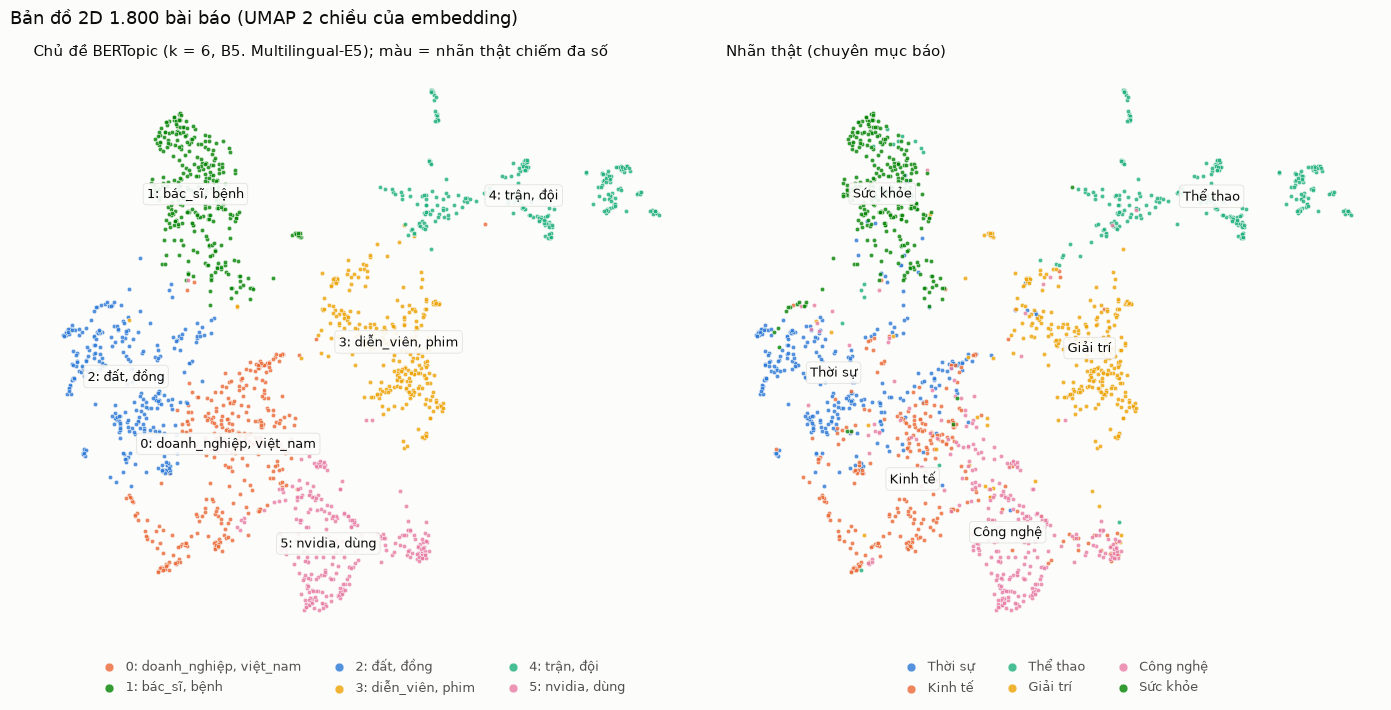

In [16]:
# Hình 1: bản đồ 2D, chủ đề BERTopic (k = 6) và nhãn thật, đặt cạnh nhau
def ve_ban_do(ax, codes, names, colors, title):
    for c in sorted(set(codes), key=lambda c: (c != NOISE_LABEL, c)):    # vẽ nhiễu trước, nằm dưới
        m = codes == c
        color = AXIS if c == NOISE_LABEL else colors[c]
        ax.scatter(xy[m, 0], xy[m, 1], s=10, color=color, alpha=0.8, linewidths=0.4, edgecolors=SURFACE,
                   label=names[c], zorder=1 if c == NOISE_LABEL else 2)
    for c in sorted(set(codes) - {NOISE_LABEL}):                         # nhãn trực tiếp ở tâm cụm
        cx, cy = np.median(xy[codes == c], axis=0)
        ax.text(cx, cy, names[c], fontsize=9, ha="center", va="center", color=INK, zorder=3,
                bbox=dict(boxstyle="round,pad=0.3", fc=SURFACE, ec=GRID, lw=0.6, alpha=0.92))
    ax.set_title(title, loc="left", color=INK)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3, frameon=False, fontsize=9,
              labelcolor=INK2, markerscale=2, handletextpad=0.3)


fig, axes = plt.subplots(1, 2, figsize=(14, 7.2))
ve_ban_do(axes[0], lab_k6, ten_chu_de(tt_k6), mau_chu_de(tt_k6),
          f"Chủ đề BERTopic (k = 6, {SHORT[best_emb]}); màu = nhãn thật chiếm đa số")
ve_ban_do(axes[1], np.array([true_idx[v] for v in y_true]), dict(enumerate(TOPICS.values())),
          dict(enumerate(SERIES)), "Nhãn thật (chuyên mục báo)")
fig.suptitle("Bản đồ 2D 1.800 bài báo (UMAP 2 chiều của embedding)", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
luu(fig, "fig1_ban_do_2d.png")

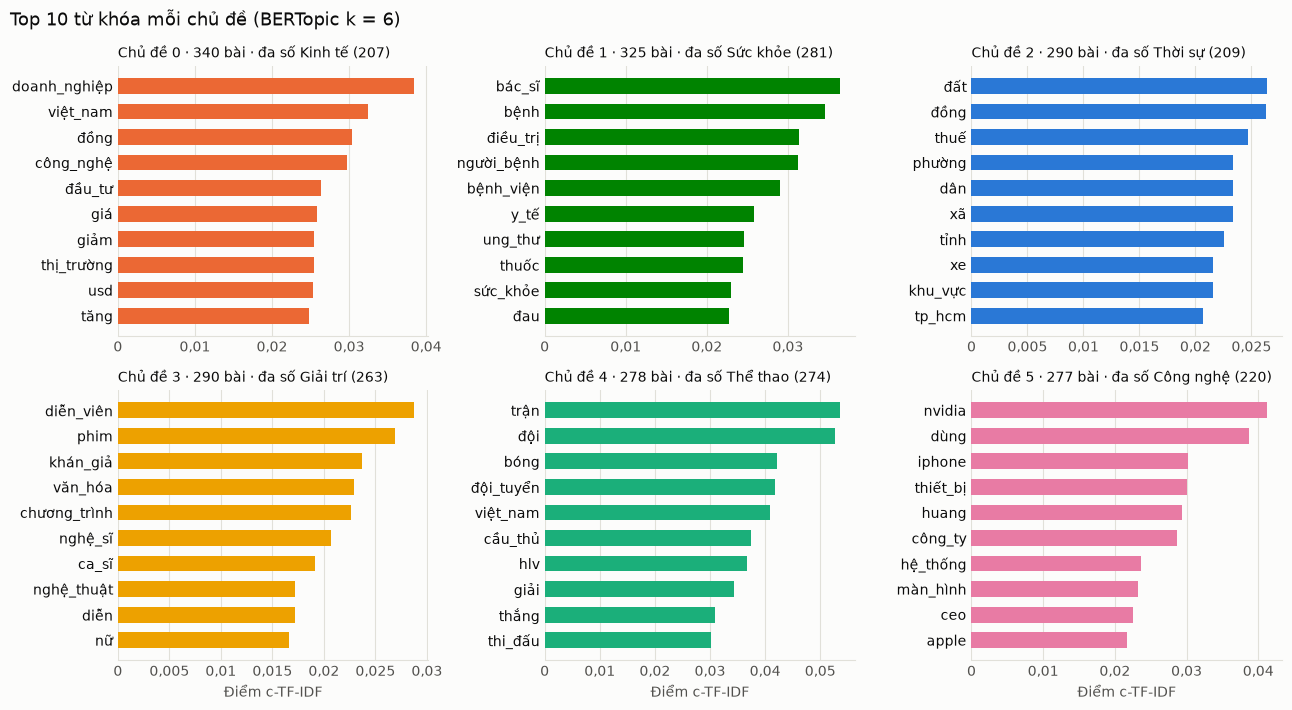

In [17]:
# Hình 2: top 10 từ khóa c-TF-IDF mỗi chủ đề (BERTopic k = 6)
topics = sorted(t for t in m_k6.get_topics() if t != NOISE_LABEL)
ncol = 3
nrow = int(np.ceil(len(topics) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(13, 3.6 * nrow))
tt = tt_k6.set_index("topic")
for ax, t in zip(axes.flat, topics):
    pairs = m_k6.get_topic(t)[:TOP_N_WORDS][::-1]
    ax.barh(range(len(pairs)), [s for _, s in pairs], height=0.62, color=mau_chu_de(tt_k6)[t])
    ax.set_yticks(range(len(pairs)), [w for w, _ in pairs], color=INK)
    ax.set_title(f"Chủ đề {t} · {tt.loc[t, 'n_docs']} bài · đa số {tt.loc[t, 'da_so']} ({tt.loc[t, 'n_da_so']})",
                 loc="left", fontsize=10)
    ax.xaxis.set_major_formatter(VN)
    ax.xaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
    ax.tick_params(length=0); ax.spines["left"].set_visible(False); ax.spines["bottom"].set_color(GRID)
for ax in axes.flat[len(topics):]:
    ax.axis("off")
for ax in axes[-1]:
    ax.set_xlabel("Điểm c-TF-IDF")
fig.suptitle("Top 10 từ khóa mỗi chủ đề (BERTopic k = 6)", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
luu(fig, "fig2_tu_khoa.png")

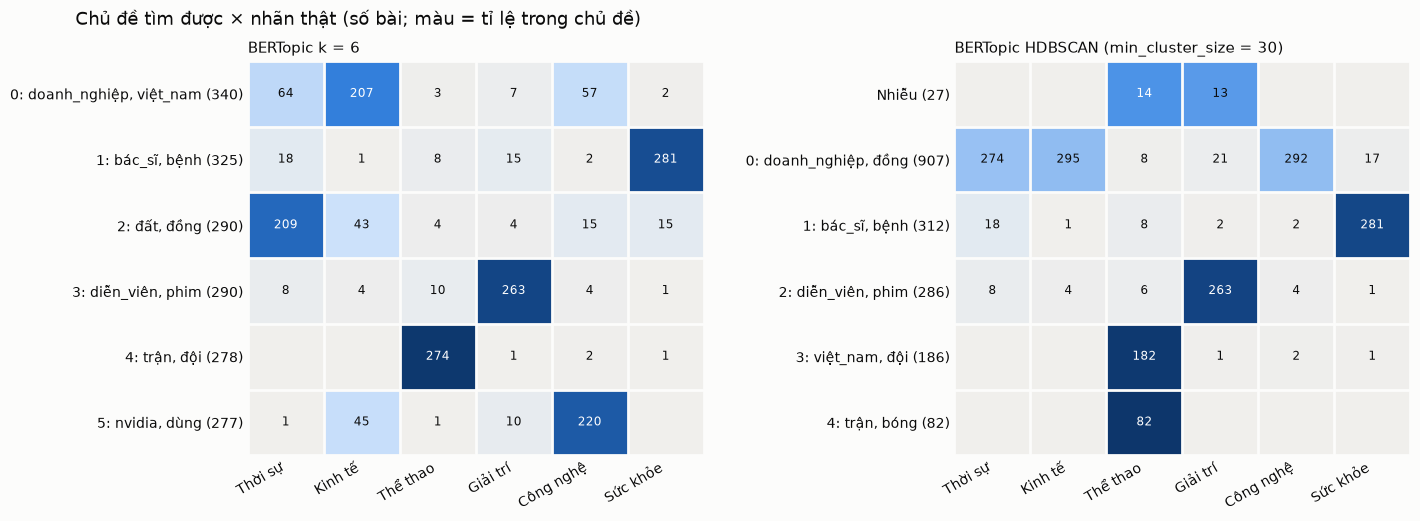

In [18]:
# Hình 3: heatmap chủ đề tìm được × nhãn thật (k = 6 và HDBSCAN). Màu = tỉ lệ trong chủ đề, số = số bài
cmap = LinearSegmentedColormap.from_list("blues", BLUES)


def ve_heatmap(ax, labels, tt, title):
    ct = pd.crosstab(labels, y_true).reindex(columns=list(TOPICS), fill_value=0)
    share = ct.div(ct.sum(axis=1), axis=0)
    ax.imshow(share.values, cmap=cmap, vmin=0, vmax=1, aspect="auto")
    names = ten_chu_de(tt)
    ax.set_yticks(range(len(ct)), [f"{names[t]} ({ct.loc[t].sum()})" for t in ct.index], color=INK)
    ax.set_xticks(range(len(TOPICS)), list(TOPICS.values()), color=INK, rotation=30, ha="right")
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]):
            v = ct.values[i, j]
            if v:
                ax.text(j, i, v, ha="center", va="center", fontsize=8.5,
                        color="#ffffff" if share.values[i, j] > 0.5 else INK)
    ax.set_xticks(np.arange(-.5, ct.shape[1]), minor=True); ax.set_yticks(np.arange(-.5, ct.shape[0]), minor=True)
    ax.grid(which="minor", color=SURFACE, lw=2); ax.tick_params(which="both", length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(title, loc="left", color=INK)


n1, n2 = len(set(lab_k6)), len(set(lab_hdb))
fig, axes = plt.subplots(1, 2, figsize=(15, 0.42 * max(n1, n2) + 2.6), gridspec_kw={"wspace": 0.55})
ve_heatmap(axes[0], lab_k6, tt_k6, "BERTopic k = 6")
ve_heatmap(axes[1], lab_hdb, tt_hdb, f"BERTopic HDBSCAN (min_cluster_size = {best_mcs})")
fig.suptitle("Chủ đề tìm được × nhãn thật (số bài; màu = tỉ lệ trong chủ đề)", x=0.01, ha="left", fontsize=13)
luu(fig, "fig3_heatmap.png")

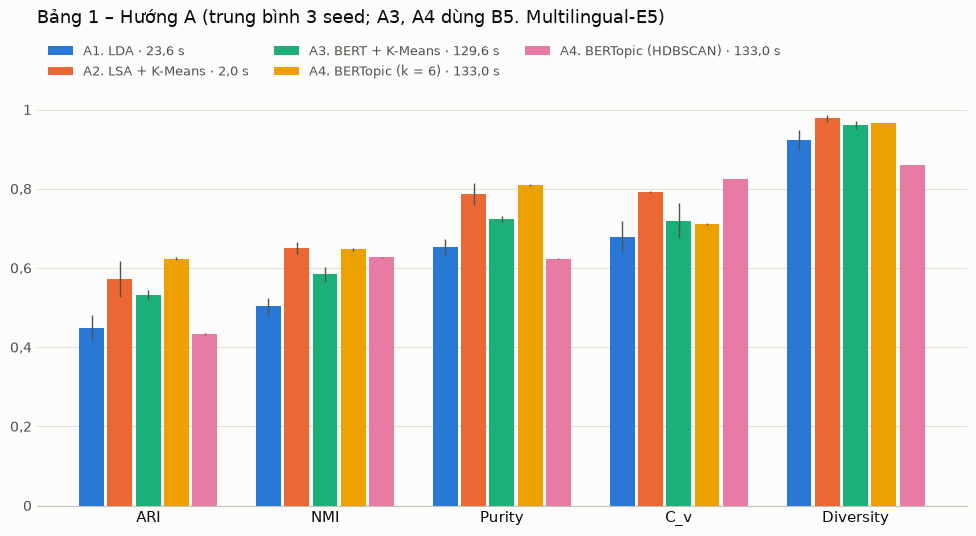

In [19]:
# Hình 4: biểu đồ cột nhóm cho Bảng 1 (thanh lỗi = độ lệch chuẩn 3 seed). Thời gian ghi trong chú thích
METRICS = [("ari", "ARI"), ("nmi", "NMI"), ("purity", "Purity"), ("cv", "C_v"), ("diversity", "Diversity")]
n = len(bang1)
w = 0.8 / n
x = np.arange(len(METRICS))
fig, ax = plt.subplots(figsize=(12, 5.4))
for i, (name, r) in enumerate(bang1.iterrows()):
    ax.bar(x + (i - (n - 1) / 2) * w, [r[m] for m, _ in METRICS], width=w * 0.88, color=SERIES[i],
           yerr=[r[f"{m}_std"] for m, _ in METRICS], error_kw=dict(ecolor=INK2, elinewidth=1, capsize=0),
           label=f"{name} · {vn(r['time_s'], 1)} s")
ax.set_xticks(x, [lab for _, lab in METRICS], color=INK, fontsize=11)
ax.set_ylim(0, 1.05); ax.yaxis.set_major_formatter(VN)
ax.yaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.tick_params(length=0); ax.spines["left"].set_visible(False); ax.spines["bottom"].set_color(AXIS)
ax.legend(ncol=3, frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), labelcolor=INK2, fontsize=9)
ax.set_title(f"Bảng 1 – Hướng A (trung bình 3 seed; A3, A4 dùng {SHORT[best_emb]})", loc="left", pad=48, fontsize=13)
luu(fig, "fig4_bang1.png")

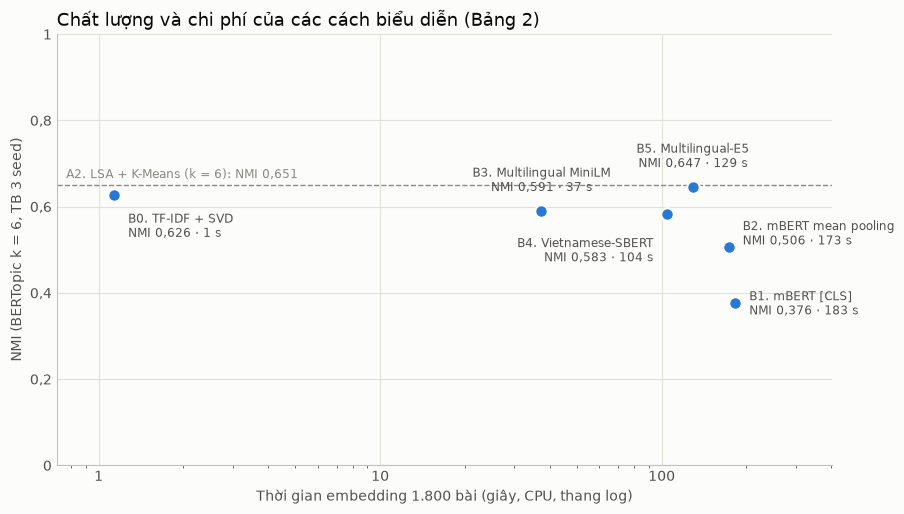

In [20]:
# Hình 5: NMI (BERTopic k = 6) theo thời gian embedding, trục x log. Đường gạch: A2 LSA + K-Means
fig, ax = plt.subplots(figsize=(10, 5.6))
ax.errorbar(bang2["emb_time"], bang2["nmi_k6"], yerr=bang2["nmi_k6_std"], fmt="o", ms=9, color=SERIES[0],
            mec=SURFACE, mew=1.5, ecolor=SERIES[0], elinewidth=1, capsize=0, zorder=3)
# vị trí nhãn (điểm offset, căn lề) chỉnh tay để không chồng nhau
NHAN = {"b0_tfidf_svd": ((10, -30), "left"), "b1_mbert_cls": ((10, -8), "left"),
        "b2_mbert_mean": ((10, 2), "left"), "b3_minilm": ((0, 14), "center"),
        "b4_vi_sbert": ((-10, -34), "right"), "b5_e5": ((0, 14), "center")}
for name, r in bang2.iterrows():
    (dx, dy), ha = NHAN.get(r["key"], ((8, 6), "left"))
    ax.annotate(f"{name}\nNMI {vn(r['nmi_k6'])} · {vn(r['emb_time'], 0)} s", (r["emb_time"], r["nmi_k6"]),
                xytext=(dx, dy), textcoords="offset points", fontsize=8.5, color=INK2, ha=ha)
lsa = bang1.loc["A2. LSA + K-Means", "nmi"]
ax.axhline(lsa, color=MUTED, lw=1, ls="--", zorder=1)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}".replace(".", ",")))
ax.set_xlim(bang2["emb_time"].min() / 1.6, bang2["emb_time"].max() * 2.2)
ax.set_ylim(0, max(1.0, bang2["nmi_k6"].max() + 0.1)); ax.yaxis.set_major_formatter(VN)
ax.text(ax.get_xlim()[0] * 1.08, lsa + 0.015, f"A2. LSA + K-Means (k = 6): NMI {vn(lsa)}",
        fontsize=8.5, color=MUTED, ha="left")
ax.set_xlabel("Thời gian embedding 1.800 bài (giây, CPU, thang log)")
ax.set_ylabel("NMI (BERTopic k = 6, TB 3 seed)")
ax.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True); ax.tick_params(length=0)
ax.set_title("Chất lượng và chi phí của các cách biểu diễn (Bảng 2)", loc="left", fontsize=13)
luu(fig, "fig5_nmi_thoi_gian.png")

## 9. Xuất bảng markdown để dán vào `ket_qua/04_bertopic_so_sanh.md`

In [21]:
def ms(mean, std, d=3):
    return f"{vn(mean, d)} ± {vn(std, d)}"


print("### Mục 2. Chọn min_cluster_size (TB 3 seed)\n")
print("| Embedding | `min_cluster_size` | Số chủ đề | Tỉ lệ nhiễu | C_v | Diversity | NMI (tham khảo) |\n|---|---|---|---|---|---|---|")
for (key, param), r in mcs_tab.iterrows():
    mark = " ✔" if key == best_emb and param == best_param else ""
    print(f"| {SHORT[key]} | {param.split('=')[1]}{mark} | {vn(r.n_topics, 1)} | {vn(100 * r.pct_noise, 1)}% "
          f"| {vn(r.cv)} | {vn(r.diversity)} | {vn(r.nmi)} |")

print("\n### Mục 3. Bảng 1\n")
print("| Phương pháp | ARI | NMI | Purity | C_v | Diversity | Thời gian (s) |\n|---|---|---|---|---|---|---|")
for name, r in bang1.iterrows():
    print(f"| {name} | " + " | ".join(ms(r[c], r[f"{c}_std"]) for c in ["ari", "nmi", "purity", "cv", "diversity"])
          + f" | {vn(r.time_s, 1)} |")

print("\n### Mục 4. Bảng 2\n")
print("| Mô hình | NMI (k=6) | ARI (k=6) | NMI (HDBSCAN) | C_v (k=6) | C_v (HDBSCAN) | Diversity (k=6) | Số chủ đề | Tỉ lệ nhiễu | Thời gian embedding (s) |")
print("|---|---|---|---|---|---|---|---|---|---|")
for name, r in bang2.iterrows():
    print(f"| {name} | {ms(r.nmi_k6, r.nmi_k6_std)} | {vn(r.ari_k6)} | {vn(r.nmi_hdb)} | {vn(r.cv_k6)} | {vn(r.cv_hdb)} "
          f"| {vn(r.div_k6)} | {vn(r.n_topics_hdb, 1)} | {vn(100 * r.noise_hdb, 1)}% | {vn(r.emb_time, 1)} |")

nt = noise_tab.agg(["mean", "std"])
print("\n### Mục 5. Xử lý cụm nhiễu (TB 3 seed)\n")
print(f"Tỉ lệ nhiễu: {vn(100 * nt.loc['mean', 'pct_noise'], 1)}%\n")
print("| Cách tính | ARI | NMI |\n|---|---|---|")
print(f"| Bỏ văn bản nhiễu | {ms(nt.loc['mean', 'ari_bo_nhieu'], nt.loc['std', 'ari_bo_nhieu'])} | {ms(nt.loc['mean', 'nmi_bo_nhieu'], nt.loc['std', 'nmi_bo_nhieu'])} |")
print(f"| Sau `reduce_outliers()` | {ms(nt.loc['mean', 'ari_reduce'], nt.loc['std', 'ari_reduce'])} | {ms(nt.loc['mean', 'nmi_reduce'], nt.loc['std', 'nmi_reduce'])} |")

for title, t in [("k = 6", tt_k6), (f"HDBSCAN, min_cluster_size = {best_mcs}", tt_hdb)]:
    print(f"\n### Mục 6. Chủ đề tìm được ({title}, seed 42)\n")
    print("| Chủ đề | Số bài | Top 10 từ khóa | Nhãn thật chiếm đa số |\n|---|---|---|---|")
    for r in t.itertuples():
        print(f"| {'Nhiễu (-1)' if r.topic == NOISE_LABEL else r.topic} | {r.n_docs} | {r.words.replace(' ', ', ') or '—'} | {r.da_so} ({r.n_da_so}) |")

### Mục 2. Chọn min_cluster_size (TB 3 seed)

| Embedding | `min_cluster_size` | Số chủ đề | Tỉ lệ nhiễu | C_v | Diversity | NMI (tham khảo) |
|---|---|---|---|---|---|---|
| B0. TF-IDF + SVD | 15 | 33,7 | 18,5% | 0,785 | 0,833 | 0,580 |
| B0. TF-IDF + SVD | 30 | 12,0 | 19,7% | 0,810 | 0,892 | 0,646 |
| B0. TF-IDF + SVD | 50 | 5,0 | 2,8% | 0,794 | 0,980 | 0,657 |
| B1. mBERT [CLS] | 15 | 2,7 | 0,4% | 0,482 | 0,900 | 0,035 |
| B1. mBERT [CLS] | 30 | 2,0 | 0,0% | 0,450 | 0,900 | 0,010 |
| B1. mBERT [CLS] | 50 | 2,0 | 0,0% | 0,450 | 0,900 | 0,010 |
| B2. mBERT mean pooling | 15 | 18,3 | 20,9% | 0,743 | 0,868 | 0,535 |
| B2. mBERT mean pooling | 30 | 9,7 | 16,5% | 0,694 | 0,918 | 0,455 |
| B2. mBERT mean pooling | 50 | 3,3 | 3,9% | 0,680 | 0,983 | 0,341 |
| B3. Multilingual MiniLM | 15 | 24,3 | 17,8% | 0,782 | 0,863 | 0,543 |
| B3. Multilingual MiniLM | 30 | 8,7 | 18,4% | 0,744 | 0,894 | 0,421 |
| B3. Multilingual MiniLM | 50 | 3,7 | 8,7% | 0,691 | 0,967 | 0,225 |
| B4. Vietnamese-SBERT | 